Mounted at /content/drive
3065 images
class  COVID  Negative
split                 
test     248       188
train   1223       922
val      276       208
class
COVID       1
Negative    0
Name: label, dtype: int64
batch: (32, 224, 224, 3) min/max: 0.0 1.0


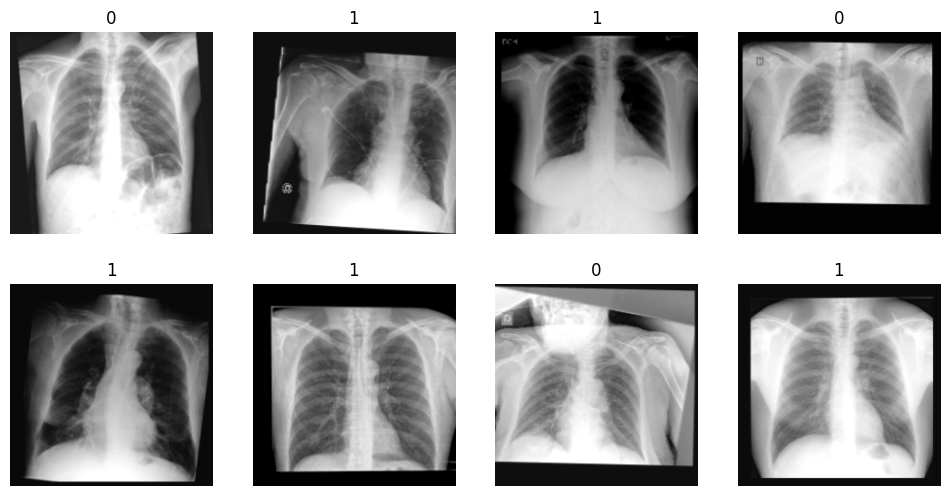

In [ ]:
#STEP 4 from CUSTOM CNN step. Same zipped clean data mounted in g drive. Same split
from google.colab import drive
drive.mount('/content/drive')

import zipfile, pandas as pd, tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers

ZIP  = "/content/drive/MyDrive/PSUPRProject_2026Sem2/bimcv_xray/modelA_V2_224.zip"
DATA = "/content/modelA__V2_224"                        # unzip to Colab's local disk (much faster than reading from Drive)
zipfile.ZipFile(ZIP).extractall(DATA)

df = pd.read_csv(f"{DATA}/modelA_224_clean_manifest.csv")
df["path"] = DATA + "/" + df["rel_path"]
print(len(df), "images")
print(df.groupby(["split", "class"]).size().unstack())
print(df.groupby("class")["label"].first())         # which class is label 1

IMG, BATCH = 224, 32

def load(path, label):
    x = tf.io.decode_png(tf.io.read_file(path), channels=1)
    x = tf.image.grayscale_to_rgb(x)                  # 3 channels, same as groupmate's make_tensor
    x = tf.cast(x, tf.float32) / 255.0                # 0-1
    return x, tf.cast(label, tf.float32)

# same augmentation as Model B (no horizontal flip)
augment = tf.keras.Sequential([
    layers.RandomRotation(0.02, fill_mode="constant"),
    layers.RandomTranslation(0.05, 0.05, fill_mode="constant"),
    layers.RandomZoom(0.1, fill_mode="constant"),
    layers.RandomBrightness(0.1, value_range=(0, 1)),
])

def make_ds(split, training=False):
    d = df[df["split"] == split]
    ds = tf.data.Dataset.from_tensor_slices((d["path"].values, d["label"].values))
    ds = ds.map(load, num_parallel_calls=tf.data.AUTOTUNE).cache()
    if training:
        ds = ds.shuffle(len(d), seed=42)
    ds = ds.batch(BATCH)
    if training:
        ds = ds.map(lambda x, y: (augment(x, training=True), y), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds = make_ds("train", training=True)
val_ds   = make_ds("val")
test_ds  = make_ds("test")

x, y = next(iter(train_ds))
print("batch:", x.shape, "min/max:", float(tf.reduce_min(x)), float(tf.reduce_max(x)))
plt.figure(figsize=(12, 6))
for i in range(8):
    plt.subplot(2, 4, i + 1); plt.imshow(x[i]); plt.title(int(y[i])); plt.axis("off")
plt.show()

In [ ]:
from tensorflow import keras
import os

SEED = 42
MODEL_DIR = "/content/drive/MyDrive/PSUPRProject_2026Sem2/models"
os.makedirs(MODEL_DIR, exist_ok=True)

tr = df[df["split"] == "train"]["label"]
class_weight = {c: len(tr) / (2 * (tr == c).sum()) for c in (0, 1)}
print("class_weight:", class_weight)

class_weight: {0: np.float64(1.163232104121475), 1: np.float64(0.8769419460343418)}


In [ ]:
# STEP 2: EfficientNetB0 Model (input 0-1, EfficientNet does its own normalisation inside)
import numpy as np
from tensorflow.keras.applications import EfficientNetB0

tf.keras.utils.set_random_seed(SEED)

base = EfficientNetB0(weights="imagenet", include_top=False, input_shape=(224, 224, 3))
base.trainable = False                                   # stage 1: frozen backbone, train only the new head

inputs = keras.Input(shape=(224, 224, 3), name="image")  # 0-1 images, same as the fusion script
x = layers.Rescaling(255.0, name="to_0_255")(inputs)     # EfficientNet expects 0-255
x = base(x, training=False)                              # keep BatchNorm frozen, also later when fine-tuning
x = layers.GlobalAveragePooling2D(name="gap")(x)
x = layers.Dense(128, activation="relu", name="dense")(x)   # 128-d encoder for the fusion MLP
x = layers.Dropout(0.5, name="dropout")(x)
outputs = layers.Dense(1, activation="sigmoid", name="output")(x)
model_E = keras.Model(inputs, outputs, name="modelA_efficientnetb0")
model_E.summary()

# fusion check: save, reload with plain load_model, pull out 'dense'
img = next(iter(val_ds))[0][:2]
model_E.save("effnet_check.keras")
reloaded = keras.models.load_model("effnet_check.keras")
enc = keras.Model(reloaded.inputs, reloaded.get_layer("dense").output)
print("encoder output:", enc.predict(img, verbose=0).shape)          # expect (2, 128)
print("same prediction after reload:", np.allclose(model_E(img), reloaded(img), atol=1e-5))

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "modelA_efficientnetb0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ to_0_255 (Rescaling)            │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,213,668 (16.07 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

encoder output: (2, 128)
same prediction after reload: True


In [ ]:
# STEP 3: stage 1 - frozen backbone, train only the head
CKPT_E = f"{MODEL_DIR}/modelD_efficientnetb0_18oct.keras"

model_E.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                loss="binary_crossentropy",
                metrics=["accuracy", keras.metrics.AUC(name="auc")])

callbacks = [
    keras.callbacks.ModelCheckpoint(CKPT_E, monitor="val_loss", save_best_only=True, mode="min", verbose=1),
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, mode="min", restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1),
    keras.callbacks.CSVLogger(CKPT_E.replace(".keras", "_stage1_log.csv")),
]

history_E1 = model_E.fit(train_ds, validation_data=val_ds, epochs=20,
                         class_weight=class_weight, callbacks=callbacks)

best_stage1_E = min(history_E1.history["val_loss"])
print("best stage-1 val_loss:", round(best_stage1_E, 4))

Epoch 1/20
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 415ms/step - accuracy: 0.5471 - auc: 0.5505 - loss: 0.7225
Epoch 1: val_loss improved from None to 0.66197, saving model to /content/drive/MyDrive/PSUPRProject_2026Sem2/models/modelD_efficientnetb0_18oct.keras

Epoch 1: finished saving model to /content/drive/MyDrive/PSUPRProject_2026Sem2/models/modelD_efficientnetb0_18oct.keras
68/68 ━━━━━━━━━━━━━━━━━━━━ 69s 654ms/step - accuracy: 0.5478 - auc: 0.5631 - loss: 0.7070 - val_accuracy: 0.5702 - val_auc: 0.6594 - val_loss: 0.6620 - learning_rate: 0.0010
Epoch 2/20
67/68 ━━━━━━━━━━━━━━━━━━━━ 0s 245ms/step - accuracy: 0.5809 - auc: 0.6109 - loss: 0.6774
Epoch 2: val_loss improved from 0.66197 to 0.65654, saving model to /content/drive/MyDrive/PSUPRProject_2026Sem2/models/modelD_efficientnetb0_18oct.keras

Epoch 2: finished saving model to /content/drive/MyDrive/PSUPRProject_2026Sem2/models/modelD_efficientnetb0_18oct.keras
68/68 ━━━━━━━━━━━━━━━━━━━━ 18s 266ms/step - accuracy: 0.5734 - auc: 0.6002 - lo

In [ ]:
# STEP 4: stage 2 - unfreeze EfficientNet's last block (block7) + top conv, keep BatchNorm frozen, low LR
base.trainable = True
for layer in base.layers:
    layer.trainable = ((layer.name.startswith("block7") or layer.name.startswith("top_"))
                       and not isinstance(layer, layers.BatchNormalization))
print("trainable backbone layers:", sum(l.trainable and len(l.weights) > 0 for l in base.layers))

model_E.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-5),   # 100x lower than stage 1
                loss="binary_crossentropy",
                metrics=["accuracy", keras.metrics.AUC(name="auc")])
model_E.summary()                                                       # trainable params should be ~1.3M

callbacks = [
    keras.callbacks.ModelCheckpoint(CKPT_E, monitor="val_loss", save_best_only=True, mode="min",
                                    initial_value_threshold=best_stage1_E, verbose=1),   # only saves if it beats stage 1
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, mode="min", restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-7, verbose=1),
    keras.callbacks.CSVLogger(CKPT_E.replace(".keras", "_stage2_log.csv")),
]

history_E2 = model_E.fit(train_ds, validation_data=val_ds, epochs=25,
                         class_weight=class_weight, callbacks=callbacks)
print("best stage-2 val_loss:", round(min(history_E2.history["val_loss"]), 4),
      "| stage 1 was:", round(best_stage1_E, 4))

trainable backbone layers: 6


Model: "modelA_efficientnetb0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ to_0_255 (Rescaling)            │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,213,668 (16.07 MB)

 Trainable params: 1,285,681 (4.90 MB)

 Non-trainable params: 2,927,987 (11.17 MB)

Epoch 1/25
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 397ms/step - accuracy: 0.6112 - auc: 0.6666 - loss: 0.6486
Epoch 1: val_loss improved from 0.62752 to 0.62401, saving model to /content/drive/MyDrive/PSUPRProject_2026Sem2/models/modelD_efficientnetb0_18oct.keras

Epoch 1: finished saving model to /content/drive/MyDrive/PSUPRProject_2026Sem2/models/modelD_efficientnetb0_18oct.keras
68/68 ━━━━━━━━━━━━━━━━━━━━ 65s 580ms/step - accuracy: 0.6103 - auc: 0.6690 - loss: 0.6433 - val_accuracy: 0.6674 - val_auc: 0.7090 - val_loss: 0.6240 - learning_rate: 1.0000e-05
Epoch 2/25
67/68 ━━━━━━━━━━━━━━━━━━━━ 0s 256ms/step - accuracy: 0.6227 - auc: 0.6974 - loss: 0.6267
Epoch 2: val_loss did not improve from 0.62401
68/68 ━━━━━━━━━━━━━━━━━━━━ 18s 263ms/step - accuracy: 0.6242 - auc: 0.6850 - loss: 0.6345 - val_accuracy: 0.6570 - val_auc: 0.7082 - val_loss: 0.6249 - learning_rate: 1.0000e-05
Epoch 3/25
67/68 ━━━━━━━━━━━━━━━━━━━━ 0s 246ms/step - accuracy: 0.6258 - auc: 0.6959 - loss: 0.6310
Epoch 3: val_loss did 

In [ ]:
# STEP 4b: stage 2b - unfreeze block6 + block7 + top conv, keep BatchNorm frozen, LR 1e-4
for layer in base.layers:
    layer.trainable = (layer.name.startswith(("block6", "block7", "top_"))
                       and not isinstance(layer, layers.BatchNormalization))

model_E.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-4),
                loss="binary_crossentropy",
                metrics=["accuracy", keras.metrics.AUC(name="auc")])
model_E.summary()                                                       # trainable params should be ~3.6M

best_so_far_E = min(best_stage1_E, min(history_E2.history["val_loss"]))
callbacks = [
    keras.callbacks.ModelCheckpoint(CKPT_E, monitor="val_loss", save_best_only=True, mode="min",
                                    initial_value_threshold=best_so_far_E, verbose=1),   # only saves if it beats 0.624
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, mode="min", restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-7, verbose=1),
    keras.callbacks.CSVLogger(CKPT_E.replace(".keras", "_stage2b_log.csv")),
]

history_E2b = model_E.fit(train_ds, validation_data=val_ds, epochs=25,
                          class_weight=class_weight, callbacks=callbacks)
print("best stage-2b val_loss:", round(min(history_E2b.history["val_loss"]), 4),
      "| best before:", round(best_so_far_E, 4))

Model: "modelA_efficientnetb0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ to_0_255 (Rescaling)            │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,213,668 (16.07 MB)

 Trainable params: 3,293,981 (12.57 MB)

 Non-trainable params: 919,687 (3.51 MB)

Epoch 1/25
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 407ms/step - accuracy: 0.5804 - auc: 0.6186 - loss: 0.6681
Epoch 1: val_loss did not improve from 0.62401
68/68 ━━━━━━━━━━━━━━━━━━━━ 72s 584ms/step - accuracy: 0.5944 - auc: 0.6402 - loss: 0.6552 - val_accuracy: 0.6818 - val_auc: 0.7153 - val_loss: 0.6298 - learning_rate: 1.0000e-04
Epoch 2/25
67/68 ━━━━━━━━━━━━━━━━━━━━ 0s 246ms/step - accuracy: 0.6195 - auc: 0.6876 - loss: 0.6334
Epoch 2: val_loss did not improve from 0.62401
68/68 ━━━━━━━━━━━━━━━━━━━━ 18s 254ms/step - accuracy: 0.6275 - auc: 0.6967 - loss: 0.6221 - val_accuracy: 0.6384 - val_auc: 0.7184 - val_loss: 0.6427 - learning_rate: 1.0000e-04
Epoch 3/25
67/68 ━━━━━━━━━━━━━━━━━━━━ 0s 251ms/step - accuracy: 0.6339 - auc: 0.7141 - loss: 0.6128
Epoch 3: val_loss did not improve from 0.62401
68/68 ━━━━━━━━━━━━━━━━━━━━ 18s 258ms/step - accuracy: 0.6415 - auc: 0.7153 - loss: 0.6113 - val_accuracy: 0.6798 - val_auc: 0.7139 - val_loss: 0.6340 - learning_rate: 1.0000e-04
Epoch 4/25
67/68 ━━━━━━━━

Stage 2b didn’t beat 0.624, so the saved file is still the stage 2 model (epoch 1). It did show us something useful, though. With block6 unfrozen, train AUC climbed from 0.76 to 0.87 while val AUC stayed between 0.70 and 0.73 and val_loss got worse, so the extra fine-tuning is learning things that only fit the training images. That’s the same pattern ResNet50 showed. My recommendation is to stop tuning and evaluate.

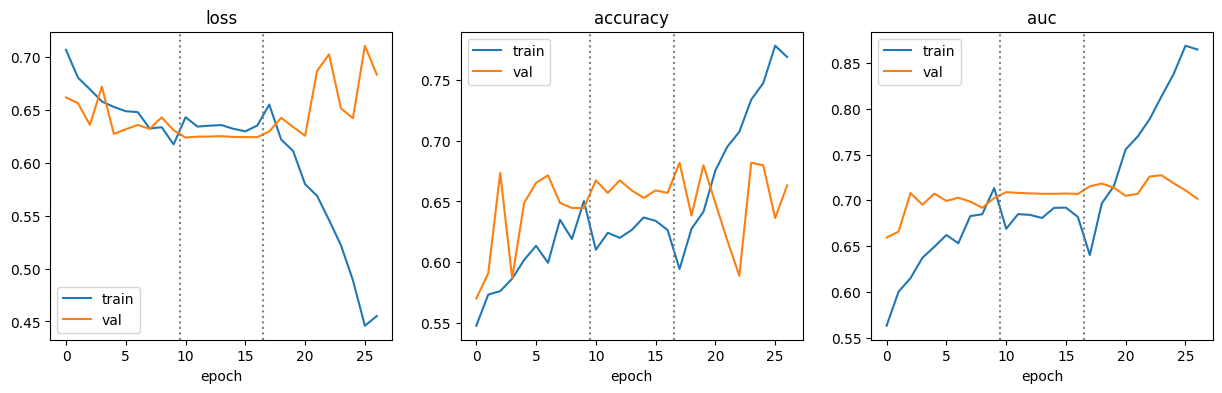

         model   level thr_from   thr   n   AUC  accuracy  sensitivity  specificity  bal_acc  TP  FN  TN  FP
EfficientNetB0   image      0.5 0.500 436 0.670     0.615        0.774        0.404    0.589 192  56  76 112
EfficientNetB0   image      val 0.513 436 0.670     0.610        0.742        0.436    0.589 184  64  82 106
EfficientNetB0 patient      0.5 0.500 282 0.619     0.582        0.737        0.434    0.586 101  36  63  82
EfficientNetB0 patient      val 0.517 282 0.619     0.571        0.679        0.469    0.574  93  44  68  77
      ResNet50   image      0.5 0.500 436 0.710     0.626        0.556        0.718    0.637 138 110 135  53
      ResNet50   image      val 0.464 436 0.710     0.665        0.641        0.697    0.669 159  89 131  57
      ResNet50 patient      0.5 0.500 282 0.702     0.642        0.562        0.717    0.640  77  60 104  41
      ResNet50 patient      val 0.444 282 0.702     0.652        0.672        0.634    0.653  92  45  92  53
    Custom CNN   im

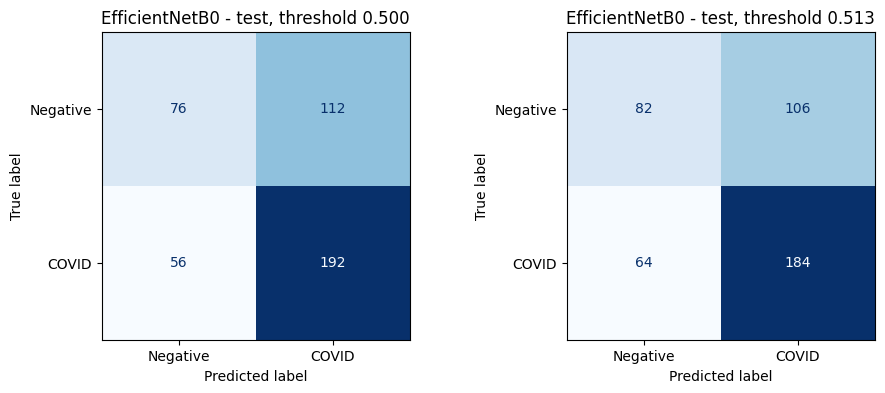

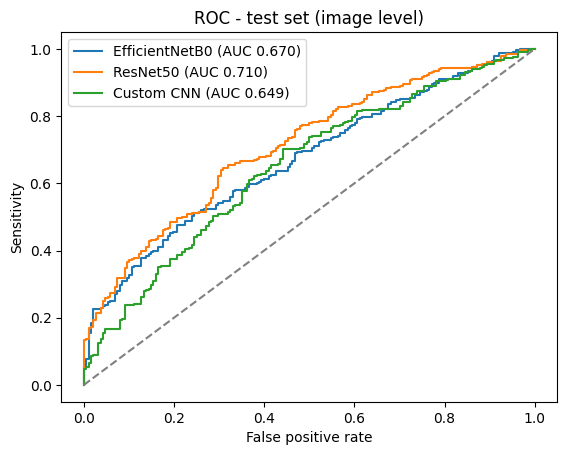

encoder output: (2, 128)


In [ ]:
# STEP 5: test-set evaluation - EfficientNetB0 vs ResNet50 vs custom CNN
import numpy as np
from sklearn.metrics import (roc_auc_score, roc_curve, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

# training curves: stage 1 | stage 2 | stage 2b (dotted lines = where each stage starts)
logs = [pd.read_csv(CKPT_E.replace(".keras", f"_{s}_log.csv")) for s in ["stage1", "stage2", "stage2b"]]
log = pd.concat(logs, ignore_index=True)
cuts = np.cumsum([len(l) for l in logs])[:-1]
plt.figure(figsize=(15, 4))
for i, m in enumerate(["loss", "accuracy", "auc"]):
    plt.subplot(1, 3, i + 1)
    plt.plot(log[m], label="train"); plt.plot(log["val_" + m], label="val")
    for c in cuts:
        plt.axvline(c - 0.5, ls=":", c="grey")
    plt.title(m); plt.xlabel("epoch"); plt.legend()
plt.show()

def report(y, p, thr=0.5):
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"thr": thr, "n": len(y), "AUC": roc_auc_score(y, p), "accuracy": (tp + tn) / len(y),
            "sensitivity": tp / (tp + fn), "specificity": tn / (tn + fp),
            "bal_acc": (tp / (tp + fn) + tn / (tn + fp)) / 2, "TP": tp, "FN": fn, "TN": tn, "FP": fp}

def youden(y, p):                      # threshold with max sensitivity + specificity - 1
    fpr, tpr, thr = roc_curve(y, p)
    return float(thr[np.argmax(tpr - fpr)])

def level_view(d, name, level):        # image rows as they are, or one row per patient (mean probability)
    if level == "image":
        return d["label"].values, d[name].values
    g = d.groupby("patient_id").agg(label=("label", "first"), prob=(name, "mean"))
    return g["label"].values, g["prob"].values

MODELS = {"EfficientNetB0": CKPT_E,
          "ResNet50":       f"{MODEL_DIR}/modelC_resnet50_18oct.keras",
          "Custom CNN":     f"{MODEL_DIR}/model_A_v2_17oct.keras"}
test_df = df[df["split"] == "test"].copy()        # same order as test_ds (not shuffled)
val_df  = df[df["split"] == "val"].copy()         # same order as val_ds
rows = []
for name, path in MODELS.items():
    m = keras.models.load_model(path)
    test_df[name] = m.predict(test_ds, verbose=0).ravel()
    val_df[name]  = m.predict(val_ds, verbose=0).ravel()
    for level in ["image", "patient"]:
        rows.append({"model": name, "level": level, "thr_from": "0.5",
                     **report(*level_view(test_df, name, level))})
        thr = youden(*level_view(val_df, name, level))                       # chosen on val only
        rows.append({"model": name, "level": level, "thr_from": "val",
                     **report(*level_view(test_df, name, level), thr)})
res = pd.DataFrame(rows)
print(res.round(3).to_string(index=False))

# EfficientNetB0 details (image level)
y, pE = test_df["label"].values, test_df["EfficientNetB0"].values
print(classification_report(y, (pE >= 0.5).astype(int), target_names=["Negative", "COVID"], digits=3))
thr_E = res.query("model == 'EfficientNetB0' and level == 'image' and thr_from == 'val'")["thr"].item()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, t in zip(axes, [0.5, thr_E]):
    ConfusionMatrixDisplay(confusion_matrix(y, (pE >= t).astype(int)),
                           display_labels=["Negative", "COVID"]).plot(cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"EfficientNetB0 - test, threshold {t:.3f}")
plt.show()

# ROC of all three models (image level)
for name in MODELS:
    fpr, tpr, _ = roc_curve(y, test_df[name])
    plt.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y, test_df[name]):.3f})")
plt.plot([0, 1], [0, 1], "--", c="grey"); plt.xlabel("False positive rate"); plt.ylabel("Sensitivity")
plt.title("ROC - test set (image level)"); plt.legend(); plt.show()

# fusion check on the saved EfficientNetB0 file
best_E = keras.models.load_model(CKPT_E)
enc = keras.Model(best_E.inputs, best_E.get_layer("dense").output)
print("encoder output:", enc.predict(next(iter(test_ds))[0][:2], verbose=0).shape)   # expect (2, 128)